In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
dir1 = os.path.dirname(os.path.abspath('..'))
if not dir1 in sys.path: sys.path.append(dir1)

In [2]:
from pathlib import Path
import pickle
import yaml
import pandas as pd
import numpy as np
import scipy.signal as ss
from numpy.fft import fft
from tqdm.auto import tqdm

import seaborn as sns
from utils.plots import *
from utils.figures import plot_metrics, print_stats
from matplotlib.ticker import StrMethodFormatter
from matplotlib.gridspec import GridSpec

from utils import models

FIG = 'fig1'
config_fpath = Path(f'{FIG}.yml')
df_fpath = Path(f'{FIG}_df.csv')

In [3]:
data_dir = Path('../../experiments/simulation_base')

def load_from_id(idx):
    obs_fpath = data_dir / 'idx' / idx / f'{idx}_sig_obs.csv'
    df_obs = pd.read_csv(obs_fpath)
    t, y_obs = df_obs.t.values, df_obs.y.values

    iir_fpath = data_dir / 'idx' / idx / 'filt' / f'{idx}_F_cheby.csv'
    df_iir = pd.read_csv(iir_fpath)
    t_iir, y_iir = df_iir.t.values, df_iir.y.values

    bpd_fpath = data_dir / 'idx' / idx / 'filt' / f'{idx}_F_bpd.csv'
    df_bpd = pd.read_csv(bpd_fpath)
    t_bpd, y_bpd = df_bpd.t.values, df_bpd.y.values

    assert np.all(np.isclose(t, t_iir))
    assert np.all(np.isclose(t, t_bpd))

    true_fpath = data_dir / 'idx' / idx / f'{idx}_soln_true.pkl'
    with open(true_fpath, 'rb') as f:
        true = pickle.load(f)
    y_true = models.evaluate(t, true['z'], true['w'], true['f_h'], true['g'])[0]

    return t, y_obs, y_iir, y_bpd, y_true


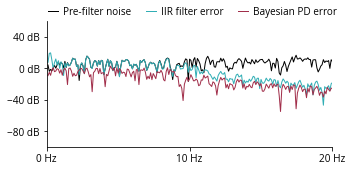

In [4]:
def est_power(signal):
    return np.mean((signal-np.mean(signal))**2)

def est_power_in_window(signal, window):
    sig = signal - np.mean(signal)
    return np.sum(sig**2 * window) / np.sum(window)

def window_same_power(signal, window):
    power = est_power_in_window(signal, window)
    sig = signal - np.mean(signal)
    sig *= window
    sig *= np.sqrt(power) / np.sqrt(est_power_in_window(sig, window))
    return sig

def aligned(signal, ref):
    sig = signal.copy()
    sig -= signal.mean()
    sig *= ref.std() / signal.std()
    sig += ref.mean()
    return sig

t, y_obs, y_iir, y_bpd, y_true = load_from_id('0001')

fs = (t.size-1)/(t.max()-t.min())
ff = np.arange(t.size) / t.size * fs

window = ss.windows.hann(y_true.size)
window /= np.sum(window)

y_true2 = window_same_power(y_true, window)
y_obs2 = window_same_power(y_obs, window)
y_iir2 = window_same_power(y_iir, window)
y_bpd2 = window_same_power(y_bpd, window)

noise = y_obs2 - y_true2
iir_err = aligned(y_iir2, y_true2) - y_true2
bpd_err = aligned(y_bpd2, y_true2) - y_true2

Y_true = 20*np.log10(np.abs(fft(y_true)))
Y_noise = 20*np.log10(np.abs(fft(noise)))
Y_iir_err = 20*np.log10(np.abs(fft(iir_err)))
Y_bpd_err = 20*np.log10(np.abs(fft(bpd_err)))


def subfigure_a():
    fa, fb = 0, 20
    win = (ff > fa) & (ff <= fb)

    lines = []
    lines += plt.plot(ff[win], Y_noise[win], c='k', lw=1, label='Pre-filter noise')
    lines += plt.plot(ff[win], Y_iir_err[win], c=cp[3], lw=1, label='IIR filter error')
    lines += plt.plot(ff[win], Y_bpd_err[win], c=cp[1], lw=1, label='Bayesian PD error')
    plt.xlim(fa, fb)
    plt.xticks([0, 10, 20])
    plt.yticks([-80, -40, 0, 40])
    plt.ylim(-100, 60)
    plt.gca().xaxis.set_major_formatter(StrMethodFormatter("{x:0.0f} Hz"))
    plt.gca().yaxis.set_major_formatter(StrMethodFormatter("{x:0.0f} dB"))

    plt.legend(lines, [ln.get_label() for ln in lines],
               loc='lower left', bbox_to_anchor=(0, 1.02),
               ncol=3, columnspacing=1.5,
               frameon=False, borderpad=0.0, borderaxespad=0.1,
               handlelength=1.0, handletextpad=0.5)

plt.figure(figsize=(5,2.5))
subfigure_a()
plt.show()

In [5]:
idx = [x.stem.split('_')[0] for x in sorted(data_dir.glob('idx/*/*_soln_bpd.pkl'))]

Y_true = np.empty((len(idx),t.size))
Y_noise = np.empty((len(idx),t.size))
Y_iir_err = np.empty((len(idx),t.size))
Y_bpd_err = np.empty((len(idx),t.size))
for i, idx in enumerate(tqdm(idx, leave=False)):
    t, y_obs, y_iir, y_bpd, y_true = load_from_id(idx)

    fs = (t.size-1)/(t.max()-t.min())
    ff = np.arange(t.size) / t.size * fs

    window = ss.windows.hann(y_true.size)
    window /= np.sum(window)

    y_true2 = window_same_power(y_true, window)
    y_obs2 = window_same_power(y_obs, window)
    y_iir2 = window_same_power(y_iir, window)
    y_bpd2 = window_same_power(y_bpd, window)

    noise = y_obs2 - y_true2
    iir_err = aligned(y_iir2, y_true2) - y_true2
    bpd_err = aligned(y_bpd2, y_true2) - y_true2

    Y_true[i] = 20*np.log10(np.abs(fft(y_true)))
    Y_noise[i] = 20*np.log10(np.abs(fft(noise)))
    Y_iir_err[i] = 20*np.log10(np.abs(fft(iir_err)))
    Y_bpd_err[i] = 20*np.log10(np.abs(fft(bpd_err)))


  0%|          | 0/100 [00:00<?, ?it/s]

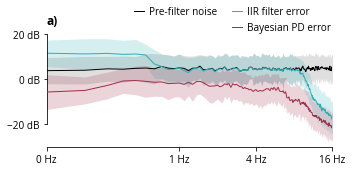

In [6]:
def subfigure_a_all(debug=False):
    fa, fb = 0, 16
    win = (ff > fa) & (ff <= fb)

    plt.plot(ff[win], Y_noise[:,win].mean(0), c='k', lw=1, zorder=1,label='Pre-filter noise')
    plt.plot([np.nan], [np.nan], lw=0, label=' ')
    plt.plot(ff[win], Y_iir_err[:,win].mean(0), c=cp[3], lw=1, zorder=2, label='IIR filter error')
    plt.plot(ff[win], Y_bpd_err[:,win].mean(0), c=cp[1], lw=1, zorder=3, label='Bayesian PD error')

    plt.fill_between(ff[win],
                     Y_noise[:,win].mean(0) - Y_noise[:,win].std(0),
                     Y_noise[:,win].mean(0) + Y_noise[:,win].std(0),
                     lw=0, color=cp[-1], zorder=-3, alpha=0.5)
    plt.fill_between(ff[win],
                     Y_iir_err[:,win].mean(0) - Y_iir_err[:,win].std(0),
                     Y_iir_err[:,win].mean(0) + Y_iir_err[:,win].std(0),
                     lw=0, color=cp[3], zorder=-2, alpha=0.2)
    plt.fill_between(ff[win],
                     Y_bpd_err[:,win].mean(0) - Y_bpd_err[:,win].std(0),
                     Y_bpd_err[:,win].mean(0) + Y_bpd_err[:,win].std(0),
                     lw=0, color=cp[1], zorder=-2, alpha=0.2)

    plt.semilogx()
    plt.xticks([ff[win][0], 1, 4, 16])

    plt.yticks([-20, 0, 20])
    plt.ylim(-30, 20)
    plt.gca().xaxis.set_major_formatter(StrMethodFormatter("{x:0.0f} Hz"))
    plt.gca().yaxis.set_major_formatter(StrMethodFormatter("{x:0.0f} dB"))

    if not debug:
        sns.despine(ax=plt.gca(), trim=True)

    plt.legend(loc='lower right', bbox_to_anchor=(1, 1),
               ncol=2, columnspacing=1.5,
               frameon=False, borderpad=0.0, borderaxespad=0.1,
               handlelength=1.0, handletextpad=0.5)
    plt.minorticks_off()
    plt.title('a)', loc='left', pad=10, fontdict={'fontweight':'bold'})

plt.figure(figsize=(5,2.5))
subfigure_a_all()
plt.show()

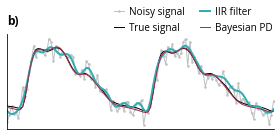

In [7]:
t, y_obs, y_iir, y_bpd, y_true = load_from_id('0001')

def subfigure_b(title='b)'):
    # ta, tb = 5.05, 6.0 # 0001, 1 pulse
    ta, tb = 5, 6.9 # 0001 2 pulses
    win = (t >= ta) & (t <= tb)
    ta, tb = t[win].min(), t[win].max()

    def aligned(sig):
        sig = sig.copy()
        sig -= y_iir.mean()
        sig *= y_true.std() / y_iir.std()
        sig += y_true.mean()
        return sig

    plt.plot(t[win], y_obs[win], '.-', c=cp[-1], lw=1, markersize=3, zorder=-1, label='Noisy signal')
    plt.plot(t[win], y_true[win], c='k', lw=1, zorder=1, label='True signal')
    plt.plot(t[win], aligned(y_iir)[win], c=cp[3], lw=2, zorder=2, label='IIR filter')
    plt.plot(t[win], aligned(y_bpd)[win], c=cp[1], lw=1, zorder=3, label='Bayesian PD')
    plt.yticks([])
    plt.xticks([])
    plt.legend(loc='lower right', bbox_to_anchor=(1, 1),
               ncol=2, columnspacing=1.5,
               frameon=False, borderpad=0.0, borderaxespad=0.1,
               handlelength=1.0, handletextpad=0.5)
    plt.title(title, loc='left', pad=10, fontdict={'fontweight':'bold'})

plt.figure(figsize=(4,2.0))
subfigure_b()
plt.show()

median metrics:
method
F_bpd      -13.300968
F_butter    -4.398486
F_cheby     -4.430129
F_nk        -5.270204
F_pyp       -4.430129
Name: loss_db, dtype: float64

	p=1.000E+00, Butterworth == Chebyshev
***	p=4.016E-17, Butterworth <> Neurokit2
	p=1.000E+00, Butterworth == PyPPG
***	p=4.016E-17, Butterworth <> Bayesian PD
***	p=3.897E-17, Chebyshev <> Neurokit2
	p=NAN, Chebyshev == PyPPG
***	p=4.016E-17, Chebyshev <> Bayesian PD
***	p=3.897E-17, Neurokit2 <> PyPPG
***	p=4.016E-17, Neurokit2 <> Bayesian PD
***	p=4.016E-17, PyPPG <> Bayesian PD



/Users/psr/opt/anaconda3/envs/pulse_deconv/lib/python3.13/site-packages/scipy/stats/_wilcoxon.py:181: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


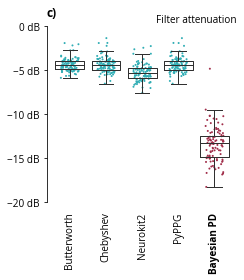

In [8]:
with open(config_fpath, 'r') as f:
    config = yaml.safe_load(f)
df = pd.read_csv(df_fpath)

y = config['y'][0]
metric = y['metric']
def subfigure_c(sub='c)', stats=False):
    title = y['name']
    methods = [x['method'] for x in y['x']]
    names = [x['name'] for x in y['x']]
    df_temp = plot_metrics(df, metric, methods, names)
    
    plt.gca().set_xmargin(0.05)
    plt.gca().yaxis.set_major_formatter(StrMethodFormatter("{x:0.0f} dB"))
    
    plt.gca().tick_params(axis="x", direction="in", pad=-61)
    plt.ylim(-28, 0)
    plt.yticks([-20, -15, -10, -5, 0])
    sns.despine(ax=plt.gca(), bottom=True, trim=True)
    labels = plt.gca().get_xticklabels()
    labels[-1].set_weight('bold')
    
    plt.title(sub, loc='left', pad=10, fontdict={'fontweight': 'bold'})
    plt.plot([np.nan], [np.nan], lw=0, label=title)
    plt.legend(loc='lower right', bbox_to_anchor=(1, 1),
               ncol=3, columnspacing=1.5,
               frameon=False, borderpad=0.0, borderaxespad=0.1,
               handlelength=1.0, handletextpad=0.5)

    if stats:
        print_stats(df, metric, methods, names, bonferroni=True)

    return df_temp

plt.figure(figsize=(3.5,4))
df_temp = subfigure_c(stats=True)
plt.show()


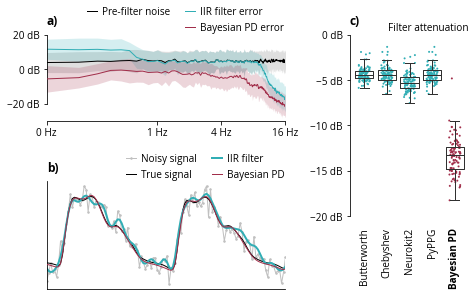

In [9]:
fig = plt.figure(figsize=(6.5,4), layout="constrained")

gs = GridSpec(2, 2, figure=fig,
              width_ratios=[2, 1], height_ratios=[4, 5],
              wspace=0.05, hspace=0.05)
ax1 = fig.add_subplot(gs[0, 0])
subfigure_a_all()
ax2 = fig.add_subplot(gs[1, 0])
subfigure_b()
ax4 = fig.add_subplot(gs[:, 1])
subfigure_c()

plt.savefig(f'{FIG}.pdf', transparent=True)
plt.savefig(f'{FIG}.png', transparent=True, dpi=200)
plt.show()